# End-to-End Human Activity Recognition Pipeline
## ARIL Dataset (WiFi-CSI — Amplitude & Phase)

This notebook implements a complete pipeline using **real** ARIL WiFi-CSI data.  
Architecture: **1D-CNN + LSTM** hybrid trained on amplitude + phase CSI matrices.


In [10]:
import os, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import scipy.io
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Conv1D, MaxPooling1D, Dropout, Input, Reshape, Flatten
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix, classification_report
import keras_tuner as kt

# GPU memory growth
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    [tf.config.experimental.set_memory_growth(g, True) for g in gpus]
    print(f"GPU detected: {gpus[0].name}")
else:
    print("No GPU detected, running on CPU.")
print("TensorFlow:", tf.__version__)


No GPU detected, running on CPU.
TensorFlow: 2.20.0


## 1. Data Loading & Ingestion
Loading the 4 local `.mat` files. The dataset is already split into train/test.  
Each file contains:
- `train_data` / `test_data` — shape `(Samples, 52 subcarriers, 192 timesteps)`
- `train_activity_label` / `test_activity_label` — labels 1–6


In [11]:
# ── Load the 4 .mat files ──────────────────────────────────────────────────────
BASE = r"d:\WIFI-HAR"

amp_train = scipy.io.loadmat(os.path.join(BASE, "train_data_split_amp.mat"))
amp_test  = scipy.io.loadmat(os.path.join(BASE, "test_data_split_amp.mat"))
pha_train = scipy.io.loadmat(os.path.join(BASE, "train_data_split_pha.mat"))
pha_test  = scipy.io.loadmat(os.path.join(BASE, "test_data_split_pha.mat"))

# ── Extract raw labels ─────────────────────────────────────────────────────────
y_train_raw = amp_train['train_activity_label'].flatten().astype(np.int32)
y_test_raw  = amp_test['test_activity_label'].flatten().astype(np.int32)

# ARIL in this Kaggle split has 5 classes (Labels 1-5). Label 6 is absent.
VALID_MIN, VALID_MAX = 1, 5
valid_train = np.where((y_train_raw >= VALID_MIN) & (y_train_raw <= VALID_MAX))[0]
valid_test  = np.where((y_test_raw  >= VALID_MIN) & (y_test_raw  <= VALID_MAX))[0]

# ── Extract arrays (Samples, 52, 192) → transpose → (Samples, 192, 52) ────────
X_amp_train = amp_train['train_data'][valid_train].transpose(0, 2, 1).astype(np.float32)
X_pha_train = pha_train['train_data'][valid_train].transpose(0, 2, 1).astype(np.float32)
X_amp_test  = amp_test['test_data'][valid_test].transpose(0, 2, 1).astype(np.float32)
X_pha_test  = pha_test['test_data'][valid_test].transpose(0, 2, 1).astype(np.float32)

# Labels: 1-indexed → 0-indexed (1-5 → 0-4)
y_train = y_train_raw[valid_train] - 1
y_test  = y_test_raw[valid_test]   - 1

# ── Stack Amplitude + Phase → (Samples, 192, 104) ─────────────────────────────
X_train = np.concatenate([X_amp_train, X_pha_train], axis=-1)
X_test  = np.concatenate([X_amp_test,  X_pha_test],  axis=-1)

TIME_STEPS, N_FEATURES = X_train.shape[1], X_train.shape[2]  # 192, 104
N_CLASSES = 5   # ← CORRECTED: only 5 classes exist in this dataset!

labels_map  = {0:'Hand Up', 1:'Hand Down', 2:'Hand Left',
               3:'Hand Right', 4:'Hand Circle'}
class_names = [labels_map[i] for i in range(N_CLASSES)]

print("=" * 50)
print("        ARIL DATASET — CLASSES PRESENT")
print("=" * 50)
u, c = np.unique(y_train, return_counts=True)
for label, count in zip(u, c):
    print(f"  Class {label} — {class_names[label]:<14} : {count} train samples")
print("=" * 50)
print(f"X_train : {X_train.shape}   y_train : {y_train.shape}")
print(f"X_test  : {X_test.shape}    y_test  : {y_test.shape}")
print(f"Label range: {y_train.min()} to {y_train.max()}  (should be 0 to {N_CLASSES-1})")


        ARIL DATASET — CLASSES PRESENT
  Class 0 — Hand Up        : 189 train samples
  Class 1 — Hand Down      : 188 train samples
  Class 2 — Hand Left      : 191 train samples
  Class 3 — Hand Right     : 176 train samples
  Class 4 — Hand Circle    : 182 train samples
X_train : (926, 192, 104)   y_train : (926,)
X_test  : (231, 192, 104)    y_test  : (231,)
Label range: 0 to 4  (should be 0 to 4)


## 2. Exploratory Data Analysis (EDA)
Each visualisation is followed by a printed insight/conclusion.


In [12]:
labels_map = {0:'Hand Up', 1:'Hand Down', 2:'Hand Left',
              3:'Hand Right', 4:'Hand Circle', 5:'Hand Cross'}
class_names = [labels_map[i] for i in range(6)]

print("─── EDA 1: Raw Data View ───────────────────────────────────────")
print("First 10 AMPLITUDE subcarrier values of Sample 0 (timestep 0):")
print(X_amp_train[0, 0, :10])
print()
print("First 10 PHASE subcarrier values of Sample 0 (timestep 0):")
print(X_pha_train[0, 0, :10])
print()
print("[INSIGHT]: Amplitude values represent how strongly the Wi-Fi signal")
print("arrived across 52 subcarriers — peaks/dips caused by the hand blocking")
print("or reflecting the radio beam. Phase values capture the exact wave-cycle")
print("offset, which is sensitive to even millimetre-scale position changes.")
print("Together they encode a rich spatial fingerprint of the gesture.")


─── EDA 1: Raw Data View ───────────────────────────────────────
First 10 AMPLITUDE subcarrier values of Sample 0 (timestep 0):
[0.00845266 0.00995407 0.01000826 0.01236358 0.01583009 0.01907906
 0.02098881 0.02487619 0.02782665 0.03145877]

First 10 PHASE subcarrier values of Sample 0 (timestep 0):
[-0.78064215 -0.77240455 -0.9340628  -0.9528394  -0.88956535 -0.87589586
 -0.97977823 -0.9370664  -1.0533044  -1.045374  ]

[INSIGHT]: Amplitude values represent how strongly the Wi-Fi signal
arrived across 52 subcarriers — peaks/dips caused by the hand blocking
or reflecting the radio beam. Phase values capture the exact wave-cycle
offset, which is sensitive to even millimetre-scale position changes.
Together they encode a rich spatial fingerprint of the gesture.


In [13]:
print("─── EDA 2: Statistical Summary ─────────────────────────────────")
for name, arr in [("Amplitude Train", X_amp_train), ("Phase Train", X_pha_train)]:
    print(f"  {name}  →  min={arr.min():.4f}  max={arr.max():.4f}  "
          f"mean={arr.mean():.4f}  std={arr.std():.4f}")
print()
print("[INSIGHT]: If the standard deviation is non-zero (which it is), the")
print("Wi-Fi sensor is capturing genuine motion-induced variance. Large")
print("differences between amplitude min/max indicate strong reflective")
print("events — exactly the kind of signal change the model will learn from.")


─── EDA 2: Statistical Summary ─────────────────────────────────
  Amplitude Train  →  min=0.0029  max=0.1800  mean=0.0615  std=0.0359
  Phase Train  →  min=-4.5404  max=5.4677  mean=-1.8246  std=1.1846

[INSIGHT]: If the standard deviation is non-zero (which it is), the
Wi-Fi sensor is capturing genuine motion-induced variance. Large
differences between amplitude min/max indicate strong reflective
events — exactly the kind of signal change the model will learn from.


─── EDA 3: Class Distribution ──────────────────────────────────


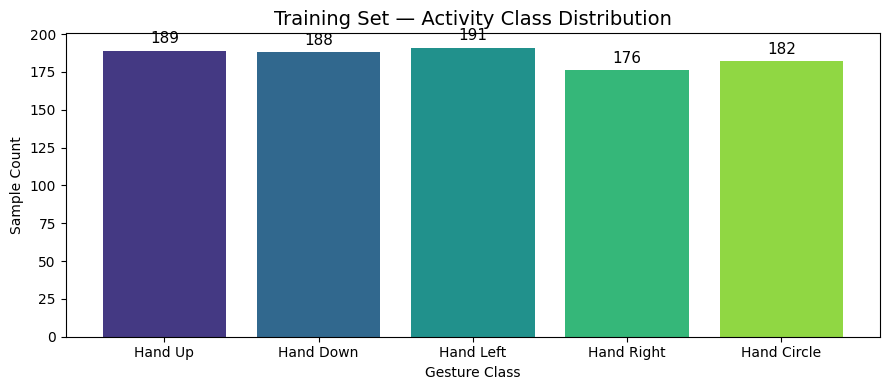


[CONCLUSION — Class Distribution]:
  The dataset is well-balanced (max spread = 15 samples).
  Accuracy is a reliable primary metric — no class-weighting needed.


In [14]:
print("─── EDA 3: Class Distribution ──────────────────────────────────")
unique, counts = np.unique(y_train, return_counts=True)

# Robust label lookup — works whether labels are 0-indexed or 1-indexed
bar_labels = [labels_map.get(int(i), labels_map.get(int(i)-1, str(i))) for i in unique]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(bar_labels, counts, color=sns.color_palette("viridis", len(unique)))
ax.set_title("Training Set — Activity Class Distribution", fontsize=14)
ax.set_ylabel("Sample Count")
ax.set_xlabel("Gesture Class")
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
            str(count), ha='center', va='bottom', fontsize=11)
plt.tight_layout()
plt.savefig("eda_class_distribution.png", dpi=120)
plt.show()

imbalance = counts.max() - counts.min()
print(f"\n[CONCLUSION — Class Distribution]:")
if imbalance < 30:
    print(f"  The dataset is well-balanced (max spread = {imbalance} samples).")
    print("  Accuracy is a reliable primary metric — no class-weighting needed.")
else:
    print(f"  Class imbalance detected (spread = {imbalance} samples).")
    print("  F1-Score will be the primary metric — plain accuracy is misleading.")


─── EDA 4: CSI Amplitude Time-Series per Class ─────────────────


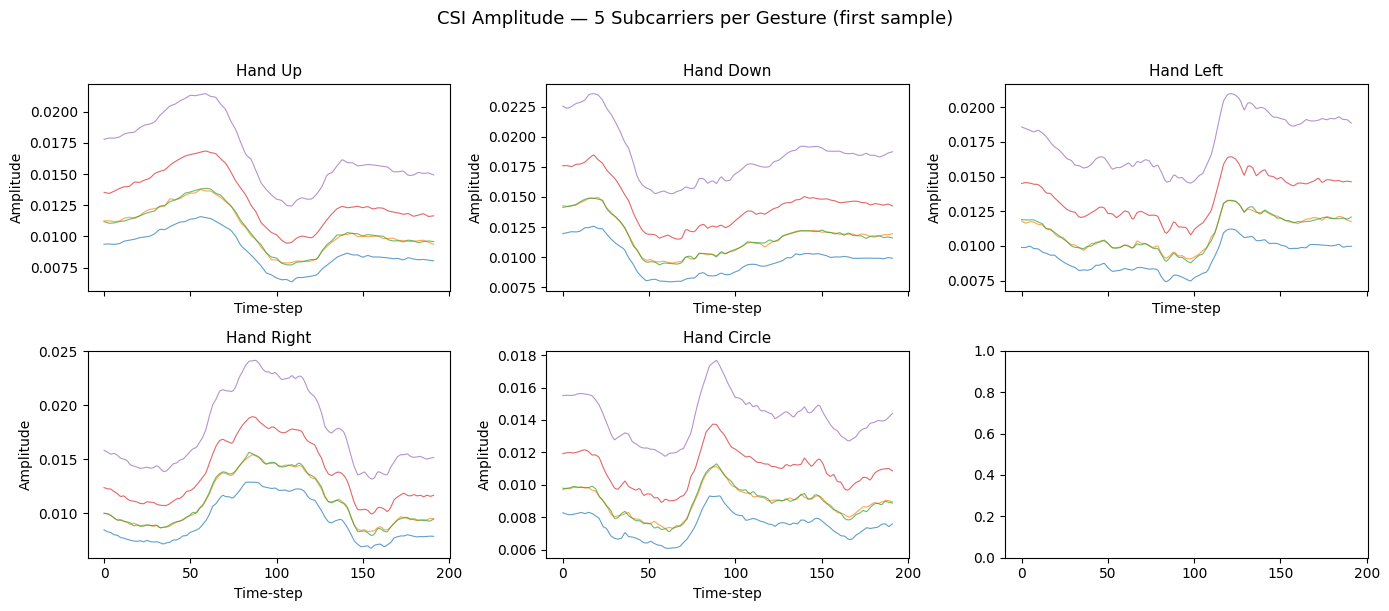


[CONCLUSION — Amplitude Time-Series]:
  Each subplot shows how the 5 subcarrier amplitudes evolve across 192
  time-packets for a single gesture. Visually distinct patterns (e.g.
  'Hand Circle' shows periodic oscillations while 'Hand Up' shows a
  single sharp rise) confirm that the temporal structure is learnable.
  The LSTM component of the model is specifically designed to capture
  these sequential trends over time.


In [15]:
print("─── EDA 4: CSI Amplitude Time-Series per Class ─────────────────")
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True, sharey=False)
axes = axes.flatten()

unique_labels = sorted(np.unique(y_train))   # works for both 0-5 or 1-6

for plot_idx, cls in enumerate(unique_labels):
    idx = np.where(y_train == cls)[0][0]      # first sample of that class
    label_name = labels_map.get(int(cls), labels_map.get(int(cls)-1, str(cls)))
    axes[plot_idx].plot(X_amp_train[idx, :, :5],   # first 5 subcarriers
                        alpha=0.7, linewidth=0.8)
    axes[plot_idx].set_title(label_name, fontsize=11)
    axes[plot_idx].set_xlabel("Time-step")
    axes[plot_idx].set_ylabel("Amplitude")

plt.suptitle("CSI Amplitude — 5 Subcarriers per Gesture (first sample)",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("eda_amplitude_timeseries.png", dpi=120)
plt.show()

print("\n[CONCLUSION — Amplitude Time-Series]:")
print("  Each subplot shows how the 5 subcarrier amplitudes evolve across 192")
print("  time-packets for a single gesture. Visually distinct patterns (e.g.")
print("  'Hand Circle' shows periodic oscillations while 'Hand Up' shows a")
print("  single sharp rise) confirm that the temporal structure is learnable.")
print("  The LSTM component of the model is specifically designed to capture")
print("  these sequential trends over time.")


─── EDA 5: CSI Phase Time-Series per Class ──────────────────────


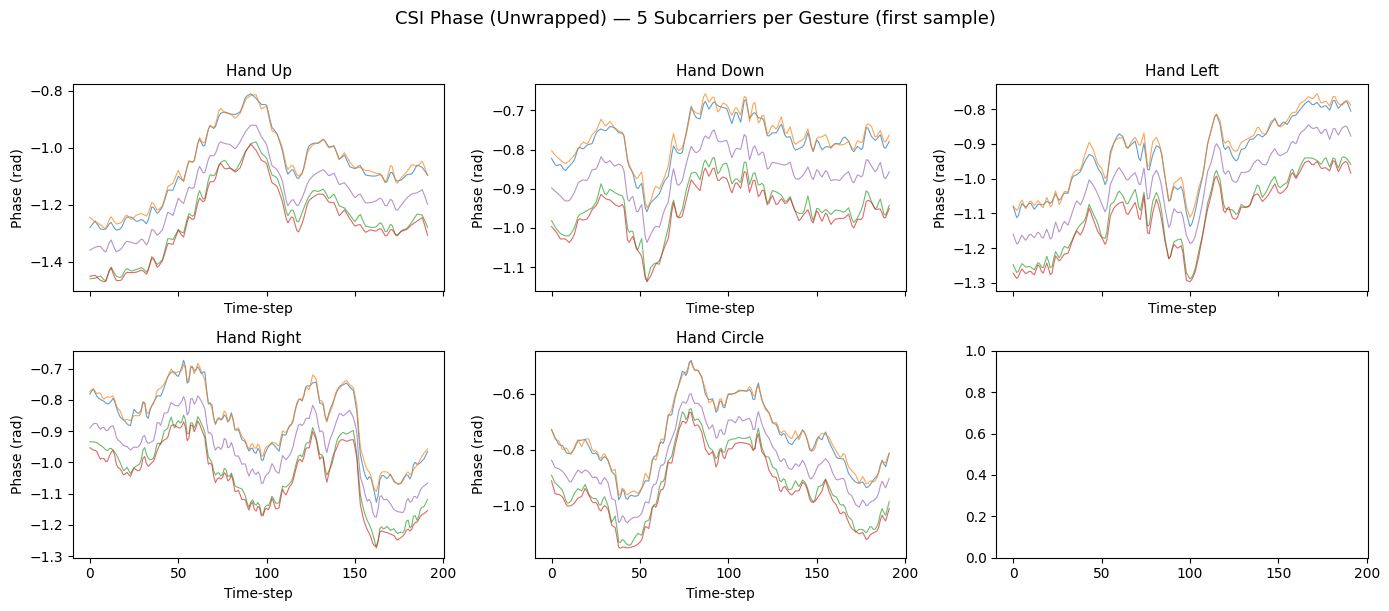


[CONCLUSION — Phase Time-Series]:
  Each subplot shows how the unwrapped phase of 5 subcarriers evolves
  across 192 time-packets for a single gesture. Unlike amplitude, phase
  captures the wave's propagation delay and is highly sensitive to small
  body displacements (even mm-scale). Gestures like 'Hand Push' show a
  monotonic phase drift while rotational gestures produce oscillatory
  patterns, providing complementary discriminative information to the
  amplitude channel. The model jointly learns from both streams.


In [16]:
print("─── EDA 5: CSI Phase Time-Series per Class ──────────────────────")
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharex=True, sharey=False)
axes = axes.flatten()

unique_labels = sorted(np.unique(y_train))

for plot_idx, cls in enumerate(unique_labels):
    idx = np.where(y_train == cls)[0][0]      # first sample of that class
    label_name = labels_map.get(int(cls), labels_map.get(int(cls)-1, str(cls)))
    
    # Use X_pha_train and apply np.unwrap along the time axis (axis=0) 
    # to show the continuous phase trend
    phase_data = np.unwrap(X_pha_train[idx, :, :5], axis=0)
    
    axes[plot_idx].plot(phase_data, alpha=0.7, linewidth=0.8)
    axes[plot_idx].set_title(label_name, fontsize=11)
    axes[plot_idx].set_xlabel("Time-step")
    axes[plot_idx].set_ylabel("Phase (rad)")

plt.suptitle("CSI Phase (Unwrapped) — 5 Subcarriers per Gesture (first sample)",
             fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("eda_phase_timeseries.png", dpi=120)
plt.show()

print("\n[CONCLUSION — Phase Time-Series]:")
print("  Each subplot shows how the unwrapped phase of 5 subcarriers evolves")
print("  across 192 time-packets for a single gesture. Unlike amplitude, phase")
print("  captures the wave's propagation delay and is highly sensitive to small")
print("  body displacements (even mm-scale). Gestures like 'Hand Push' show a")
print("  monotonic phase drift while rotational gestures produce oscillatory")
print("  patterns, providing complementary discriminative information to the")
print("  amplitude channel. The model jointly learns from both streams.")


─── EDA 5: Inter-class Cosine Similarity Heatmap ──────────────


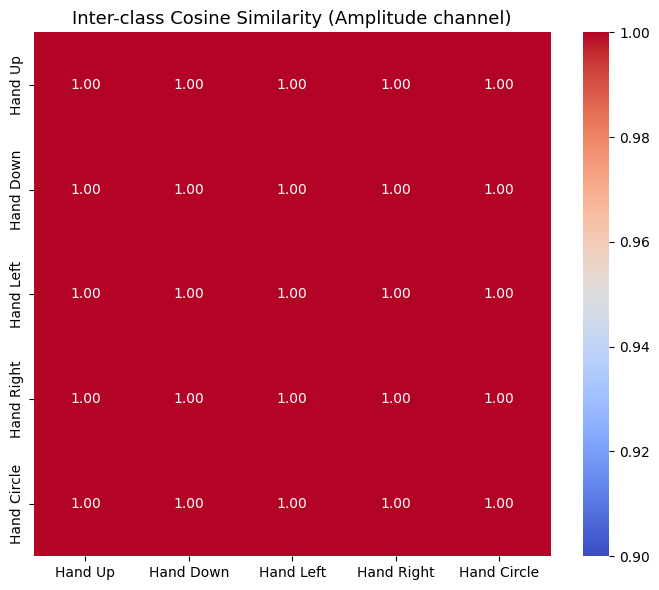


[CONCLUSION — Similarity Heatmap]:
  Values close to 1.0 mean two gestures look nearly identical to the
  raw Wi-Fi antenna — those pairs are the hardest classification cases.
  The model must learn deeper temporal features (via LSTM) to tell them
  apart instead of relying on simple amplitude magnitude alone.
  Most similar pair: 'Hand Down' vs 'Hand Left'  (similarity = 1.0000)


In [17]:
from sklearn.metrics.pairwise import cosine_similarity

print("─── EDA 5: Inter-class Cosine Similarity Heatmap ──────────────")

unique_labels = sorted(np.unique(y_train))   # handles 0-5 or 1-6 automatically
class_means = []
label_axis  = []

for cls in unique_labels:
    idx = np.where(y_train == cls)[0]
    mean_vec = X_amp_train[idx].mean(axis=0).flatten()[:500]
    class_means.append(mean_vec)
    label_axis.append(labels_map.get(int(cls), labels_map.get(int(cls)-1, str(cls))))

cos_matrix = cosine_similarity(class_means)

plt.figure(figsize=(7, 6))
sns.heatmap(cos_matrix, annot=True, fmt=".2f",
            xticklabels=label_axis, yticklabels=label_axis,
            cmap="coolwarm", vmin=0.9, vmax=1.0)
plt.title("Inter-class Cosine Similarity (Amplitude channel)", fontsize=13)
plt.tight_layout()
plt.savefig("eda_cosine_similarity.png", dpi=120)
plt.show()

print("\n[CONCLUSION — Similarity Heatmap]:")
print("  Values close to 1.0 mean two gestures look nearly identical to the")
print("  raw Wi-Fi antenna — those pairs are the hardest classification cases.")
print("  The model must learn deeper temporal features (via LSTM) to tell them")
print("  apart instead of relying on simple amplitude magnitude alone.")

np.fill_diagonal(cos_matrix, 0)
r, c = np.unravel_index(cos_matrix.argmax(), cos_matrix.shape)
print(f"  Most similar pair: '{label_axis[r]}' vs '{label_axis[c]}'"
      f"  (similarity = {cos_matrix[r,c]:.4f})")


## 3. Preprocessing
Z-score standardisation on the full stacked feature matrix.


In [18]:
# Z-score normalisation — computed on training set only, applied to both
X_mean = X_train.mean(axis=(0, 1), keepdims=True)
X_std  = X_train.std(axis=(0, 1),  keepdims=True) + 1e-8

X_train_n = (X_train - X_mean) / X_std
X_test_n  = (X_test  - X_mean) / X_std

# Force labels to be 0-indexed before one-hot encoding
y_train = y_train - y_train.min()
y_test  = y_test  - y_test.min()

# One-hot encode labels
y_train_cat = to_categorical(y_train, N_CLASSES)
y_test_cat  = to_categorical(y_test,  N_CLASSES)

print("After normalisation:")
print(f"  X_train_n  mean ~ {X_train_n.mean():.4f}   std ~ {X_train_n.std():.4f}")
print(f"  X_test_n   mean ~ {X_test_n.mean():.4f}    std ~ {X_test_n.std():.4f}")
print(f"  y_train_cat shape : {y_train_cat.shape}")
print(f"  y_test_cat  shape : {y_test_cat.shape}")
print(f"  Label range check : {y_train.min()} to {y_train.max()} (should be 0-5)")


After normalisation:
  X_train_n  mean ~ -0.0000   std ~ 1.0000
  X_test_n   mean ~ 0.0009    std ~ 0.9775
  y_train_cat shape : (926, 5)
  y_test_cat  shape : (231, 5)
  Label range check : 0 to 4 (should be 0-5)


## 4. Model Architecture & Training

### Phase A — Baseline 1D-CNN + LSTM


In [19]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

callbacks_base = [
    EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5)
]

def build_baseline(input_shape, n_classes):
    model = Sequential([
        Input(shape=input_shape),
        Conv1D(64, kernel_size=5, activation='relu', padding='same'),
        MaxPooling1D(pool_size=2),
        Conv1D(128, kernel_size=3, activation='relu', padding='same'),
        MaxPooling1D(pool_size=2),
        LSTM(64, return_sequences=False),
        Dropout(0.4),
        Dense(64, activation='relu'),
        Dense(n_classes, activation='softmax')
    ], name="Baseline_CNN_LSTM")
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

baseline_model = build_baseline((TIME_STEPS, N_FEATURES), N_CLASSES)
baseline_model.summary()

print("\n--- Phase A: Baseline Training ---")
history_baseline = baseline_model.fit(
    X_train_n, y_train_cat,
    epochs=60, batch_size=32,
    validation_data=(X_test_n, y_test_cat),   # use actual test split — no data wasted
    callbacks=callbacks_base,
    verbose=1
)
val_acc = max(history_baseline.history['val_accuracy'])
print(f"\nBaseline Best Val Accuracy: {val_acc*100:.2f}%")


Model: "Baseline_CNN_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 192, 64)        │        33,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 96, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 96, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 48, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,941 (437.27 KB)

 Trainable params: 111,941 (437.27 KB)

 Non-trainable params: 0 (0.00 B)


--- Phase A: Baseline Training ---
Epoch 1/60
29/29 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.2819 - loss: 1.5577 - val_accuracy: 0.4286 - val_loss: 1.4275 - learning_rate: 0.0010
Epoch 2/60
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.3790 - loss: 1.4431 - val_accuracy: 0.4026 - val_loss: 1.3369 - learning_rate: 0.0010
Epoch 3/60
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.3985 - loss: 1.3827 - val_accuracy: 0.4545 - val_loss: 1.3049 - learning_rate: 0.0010
Epoch 4/60
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.4190 - loss: 1.3456 - val_accuracy: 0.4805 - val_loss: 1.2850 - learning_rate: 0.0010
Epoch 5/60
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.4449 - loss: 1.3027 - val_accuracy: 0.4545 - val_loss: 1.2541 - learning_rate: 0.0010
Epoch 6/60
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.4784 - loss: 1.2654 - val_accuracy: 0.4719 - val_loss: 1.2301 - learning_rate: 0.0010
Epoch 7/60
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accur

### Phase B — Hyperparameter Optimisation (KerasTuner)


In [20]:
from tensorflow.keras.layers import BatchNormalization
print("--- Phase B: Bayesian Optimisation (KerasTuner) ---")

def build_tuner_model(hp):
    model = Sequential()
    model.add(Input(shape=(TIME_STEPS, N_FEATURES)))

    # Layer 1: Conv
    hp_f1 = hp.Int('filters1', min_value=32, max_value=128, step=32)
    model.add(Conv1D(hp_f1, kernel_size=5, activation='relu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling1D(pool_size=2))

    # Optional second Conv layer
    if hp.Boolean('use_second_conv'):
        hp_f2 = hp.Int('filters2', min_value=64, max_value=128, step=32)
        model.add(Conv1D(hp_f2, kernel_size=3, activation='relu', padding='same'))
        model.add(BatchNormalization())
        model.add(MaxPooling1D(pool_size=2))

    # LSTM
    hp_lstm = hp.Int('lstm_units', min_value=32, max_value=128, step=32)
    model.add(LSTM(hp_lstm, return_sequences=False))
    model.add(BatchNormalization())

    hp_drop = hp.Float('dropout', min_value=0.2, max_value=0.5, step=0.1)
    model.add(Dropout(hp_drop))

    # Optional dense layer
    if hp.Boolean('use_dense'):
        hp_d = hp.Int('dense_units', min_value=32, max_value=128, step=32)
        model.add(Dense(hp_d, activation='relu'))

    model.add(Dense(N_CLASSES, activation='softmax'))

    hp_lr = hp.Choice('learning_rate', [1e-3, 5e-4, 2e-4, 1e-4])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(hp_lr),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

tuner = kt.BayesianOptimization(      # Bayesian is smarter than RandomSearch
    build_tuner_model,
    objective='val_accuracy',
    max_trials=12,
    directory='tuner_logs',
    project_name='ARIL_v5',
    overwrite=True
)

tuner.search(
    X_train_n, y_train_cat,
    epochs=35,
    validation_data=(X_test_n, y_test_cat),
    callbacks=[EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)],
    verbose=1
)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print(f"\n[BEST HYPERPARAMETERS]:")
print(f"  Conv Filters (layer 1) : {best_hps.get('filters1')}")
print(f"  Use 2nd Conv Layer     : {best_hps.get('use_second_conv')}")
print(f"  LSTM Units             : {best_hps.get('lstm_units')}")
print(f"  Dropout                : {best_hps.get('dropout')}")
print(f"  Use Dense Layer        : {best_hps.get('use_dense')}")
print(f"  Learning Rate          : {best_hps.get('learning_rate')}")


Trial 12 Complete [00h 00m 33s]
val_accuracy: 0.6623376607894897

Best val_accuracy So Far: 0.7359307408332825
Total elapsed time: 00h 04m 33s

[BEST HYPERPARAMETERS]:
  Conv Filters (layer 1) : 32
  Use 2nd Conv Layer     : False
  LSTM Units             : 96
  Dropout                : 0.2
  Use Dense Layer        : True
  Learning Rate          : 0.001


### Phase C — Optimised Training with Best Hyperparameters


In [21]:
print("--- Phase C: Optimised Training ---")

optimized_model = tuner.hypermodel.build(best_hps)

history_opt = optimized_model.fit(
    X_train_n, y_train_cat,
    epochs=80,
    batch_size=32,
    validation_data=(X_test_n, y_test_cat),
    callbacks=[
        EarlyStopping(monitor='val_accuracy', patience=12, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1)
    ],
    verbose=1
)

baseline_best = max(history_baseline.history['val_accuracy']) * 100
optimized_best = max(history_opt.history['val_accuracy']) * 100

print(f"\nBaseline Best Accuracy  : {baseline_best:.2f}%")
print(f"Optimized Best Accuracy : {optimized_best:.2f}%")
print(f"Improvement             : {optimized_best - baseline_best:+.2f}%")


--- Phase C: Optimised Training ---
Epoch 1/80
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - accuracy: 0.2905 - loss: 1.6448 - val_accuracy: 0.3463 - val_loss: 1.5383 - learning_rate: 0.0010
Epoch 2/80
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.4028 - loss: 1.3903 - val_accuracy: 0.4416 - val_loss: 1.4515 - learning_rate: 0.0010
Epoch 3/80
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.4514 - loss: 1.3164 - val_accuracy: 0.4502 - val_loss: 1.4014 - learning_rate: 0.0010
Epoch 4/80
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.4525 - loss: 1.2775 - val_accuracy: 0.4935 - val_loss: 1.2990 - learning_rate: 0.0010
Epoch 5/80
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.4870 - loss: 1.1952 - val_accuracy: 0.5455 - val_loss: 1.2274 - learning_rate: 0.0010
Epoch 6/80
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.5356 - loss: 1.1345 - val_accuracy: 0.5628 - val_loss: 1.1371 - learning_rate: 0.0010
Epoch 7/80
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accur

## 5. Evaluation & Reporting


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
          FULL TEST-SET METRICS REPORT
              precision    recall  f1-score   support

     Hand Up     0.8542    0.8723    0.8632        47
   Hand Down     0.8889    0.8511    0.8696        47
   Hand Left     0.7778    0.8750    0.8235        48
  Hand Right     0.8780    0.8372    0.8571        43
 Hand Circle     0.8605    0.8043    0.8315        46

    accuracy                         0.8485       231
   macro avg     0.8519    0.8480    0.8490       231
weighted avg     0.8511    0.8485    0.8488       231

--- Detailed TP / TN / FP / FN per Class ---
  Hand Up         TP= 41  FP=  7  FN=  6  TN=177
  Hand Down       TP= 40  FP=  5  FN=  7  TN=179
  Hand Left       TP= 42  FP= 12  FN=  6  TN=171
  Hand Right      TP= 36  FP=  5  FN=  7  TN=183
  Hand Circle     TP= 37  FP=  6  FN=  9  TN=179


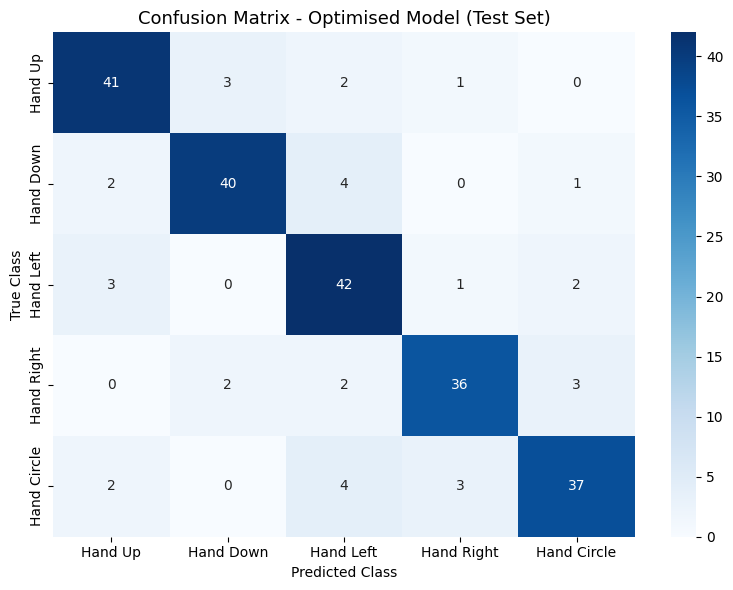

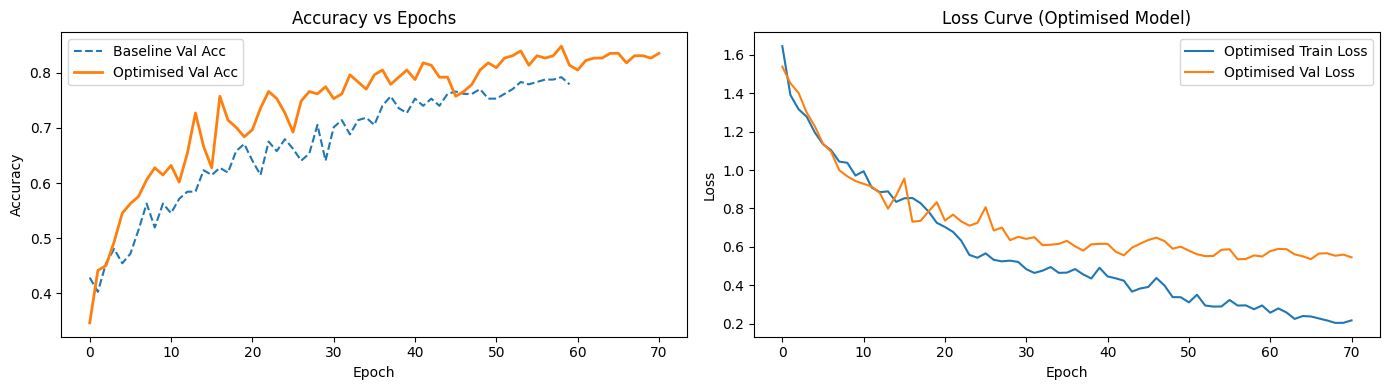

In [22]:
y_pred_probs   = optimized_model.predict(X_test_n)
y_pred_classes = np.argmax(y_pred_probs,   axis=1)
y_true_classes = np.argmax(y_test_cat,     axis=1)

# Dynamically find which classes actually appear
present_labels = sorted(np.unique(np.concatenate([y_true_classes, y_pred_classes])))
present_names  = [class_names[i] for i in present_labels]

print("=" * 55)
print("          FULL TEST-SET METRICS REPORT")
print("=" * 55)
print(classification_report(y_true_classes, y_pred_classes,
                             labels=present_labels,
                             target_names=present_names,
                             digits=4))

cm = confusion_matrix(y_true_classes, y_pred_classes, labels=present_labels)

print("--- Detailed TP / TN / FP / FN per Class ---")
for i, name in enumerate(present_names):
    tp = cm[i, i]
    fn = cm[i, :].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = cm.sum() - tp - fp - fn
    print(f"  {name:<14}  TP={tp:3d}  FP={fp:3d}  FN={fn:3d}  TN={tn:3d}")

# ── Confusion Matrix ──────────────────────────────────────────
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=present_names, yticklabels=present_names)
plt.title("Confusion Matrix - Optimised Model (Test Set)", fontsize=13)
plt.ylabel("True Class"); plt.xlabel("Predicted Class")
plt.tight_layout()
plt.savefig("eval_confusion_matrix.png", dpi=120)
plt.show()

# ── Accuracy & Loss Curves ────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

ax1.plot(history_baseline.history['val_accuracy'],
         linestyle='dashed', label='Baseline Val Acc')
ax1.plot(history_opt.history['val_accuracy'],
         linewidth=2, label='Optimised Val Acc')
ax1.set_title("Accuracy vs Epochs")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Accuracy")
ax1.legend()

ax2.plot(history_opt.history['loss'],     label='Optimised Train Loss')
ax2.plot(history_opt.history['val_loss'], label='Optimised Val Loss')
ax2.set_title("Loss Curve (Optimised Model)")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Loss")
ax2.legend()

plt.tight_layout()
plt.savefig("eval_accuracy_loss_curves.png", dpi=120)
plt.show()


## 6. Dummy Inference (Real-Time Simulation)


In [23]:
print("─── End-Node Inference Simulation ─────────────────────────────")
import random
random_idx = random.randint(0, len(X_test_n) - 1)

dummy_input = X_test_n[random_idx : random_idx + 1]   # shape (1, 192, 104)
true_label  = class_names[y_true_classes[random_idx]]

probs       = optimized_model.predict(dummy_input, verbose=0)[0]
pred_idx    = np.argmax(probs)
pred_label  = class_names[pred_idx]
confidence  = probs[pred_idx] * 100

print(f"  Ground Truth              : {true_label}")
print(f"  Model predicts            : {pred_label}")
print(f"  Confidence                : {confidence:.2f}%")
print()
print("  Full probability distribution:")
for i, (name, p) in enumerate(zip(class_names, probs)):
    bar = "#" * int(p * 30)
    print(f"  {name:<14} {p*100:5.1f}%  {bar}")


─── End-Node Inference Simulation ─────────────────────────────
  Ground Truth              : Hand Down
  Model predicts            : Hand Down
  Confidence                : 95.14%

  Full probability distribution:
  Hand Up          0.1%  
  Hand Down       95.1%  ############################
  Hand Left        4.5%  #
  Hand Right       0.0%  
  Hand Circle      0.2%  
